<a href="https://colab.research.google.com/github/fadilaha/Ising-Model-on-Social-Opinion-Dynamic/blob/main/sentiment_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment forecasting: XGBoost vs LightGBM vs VAR

Run the cells from top to bottom. Each model has its own cell (steps 6, 7, 8),
so you can run, change or re-run one model without touching the others.

1. Settings: **edit this cell** (column names, timezone)
2. Libraries
3. Load and merge the monthly files
4. Group posts into time bins + overview plot
5. Shared tools (features, walk-forward test, scoring) + the "no change" baseline
6. XGBoost
7. LightGBM
8. VAR
9. Compare all models + save results

## 1. Settings

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
USE_DRIVE   = True
PROJECT_DIR = '/content/drive/MyDrive/sentiment_project'   # folder on the Drive
DATA_FOLDER = 'Raw Data'               # subfolder containing the monthly files (csv / xlsx)

TIME_COL  = 'Date'           # timestamp column name in the files
LABEL_COL = 'Sentiment'            # sentiment label column name
INPUT_TZ  = 'Asia/Jakarta'         # timezone of the timestamps in the files
LOCAL_TZ  = 'Asia/Jakarta'         # timezone used for binning (WIB)

TARGET     = 'net'                 # 'net' = (pos - neg)/n, or 'share_pos', 'share_neu', 'share_neg'
FREQS      = ['1h', '6h', '12h', '1D']
HORIZONS_H = [1, 6, 12, 24, 72, 168]   # forecast horizons in hours. Horizons: how far the duration of time that will be predicted.
TEST_START = None                  # e.g. '2026-05-01'; None = first day of the last month
FOLD_DAYS  = 7                     # retrain every 7 days during the test period. Every 7 days, the models are retrained from scratch using all the data available up to that point.
OUT_DIR    = 'results'

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
import os
os.chdir(PROJECT_DIR)
print('Working in', os.getcwd(), '| files in data:', sorted(os.listdir(DATA_FOLDER)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/MyDrive/sentiment_project | files in data: ['prabowo26_agustus.xlsx', 'prabowo26_april.xlsx', 'prabowo26_februari.xlsx', 'prabowo26_januari.xlsx', 'prabowo26_juli.xlsx', 'prabowo26_juni.xlsx', 'prabowo26_maret.xlsx', 'prabowo26_mei.xlsx', 'prabowo26_sept.xlsx']


## 2. Libraries

In [14]:
!pip install -q xgboost lightgbm
import glob, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import lightgbm as lgb
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='X does not have valid feature names')
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__)

xgboost 3.4.1 | lightgbm 4.6.0


## 3. Load and merge the monthly files
Check the printout to ensure that every month present, few (to no) unreadable timestamps, and all label values are recognised.

In [15]:
LABEL_MAP = {
    'positive': 1, 'positif': 1, 'pos': 1, '1': 1, '1.0': 1, '+1': 1,
    'neutral': 0, 'netral': 0, 'neu': 0, '0': 0, '0.0': 0,
    'negative': -1, 'negatif': -1, 'neg': -1, '-1': -1, '-1.0': -1,
}
cols = [TIME_COL, LABEL_COL] + ([ID_COL] if ID_COL else [])

def read_any(path):
    """Read a file, finding the header row automatically (e.g. when row 1 is empty)."""
    p = path.lower()
    if p.endswith('.parquet'):
        return pd.read_parquet(path, columns=cols)
    is_xl = p.endswith(('.xlsx', '.xls'))
    peek = (pd.read_excel(path, header=None, nrows=20) if is_xl
            else pd.read_csv(path, header=None, nrows=20))
    hdr = next((i for i, r in peek.iterrows()
                if set(cols) <= set(r.astype(str).str.strip())), None)
    if hdr is None:
        raise ValueError(f'{os.path.basename(path)}: could not find columns {cols} in the first '
                         f'20 rows. Check the names in the settings cell (they are case-sensitive).')
    d = (pd.read_excel(path, header=hdr) if is_xl else pd.read_csv(path, header=hdr))
    d.columns = d.columns.astype(str).str.strip()
    return d[cols]

files = sorted(f for f in glob.glob(os.path.join(DATA_FOLDER, '*'))
               if f.lower().endswith(('.csv', '.xlsx', '.xls', '.parquet')))
parts = []
for f in files:
    d = read_any(f)
    print(f'{os.path.basename(f):40s} {len(d):>10,} rows')
    parts.append(d)
raw = pd.concat(parts, ignore_index=True)
if ID_COL:
    n0 = len(raw); raw = raw.drop_duplicates(subset=ID_COL)
    print(f'{n0 - len(raw):,} duplicate posts removed (same {ID_COL})')

t = pd.to_datetime(raw[TIME_COL], errors='coerce', format='mixed')
if t.dt.tz is None:
    t = t.dt.tz_localize(INPUT_TZ, ambiguous='NaT', nonexistent='NaT')
t = t.dt.tz_convert(LOCAL_TZ)
lab = raw[LABEL_COL].astype(str).str.strip().str.lower().map(LABEL_MAP)

print(f'\nTotal rows: {len(raw):,} | unreadable timestamps: {t.isna().sum():,} '
      f'| unrecognised labels: {lab.isna().sum():,}')
if lab.isna().any():
    print('  examples of unrecognised labels:', raw.loc[lab.isna(), LABEL_COL].astype(str).unique()[:10])
posts = pd.DataFrame({'time': t, 'label': lab}).dropna()
posts['label'] = posts['label'].astype(int)
del raw, parts, t, lab

print(f'Kept {len(posts):,} posts, {posts.time.min()} -> {posts.time.max()}')
print('\nPosts per month:')
print(posts.time.dt.tz_localize(None).dt.to_period('M').value_counts().sort_index().to_string())
print('\nLabels:', posts.label.map({1: 'positive', 0: 'neutral', -1: 'negative'}).value_counts().to_dict())
print('\nPosts by hour of day (should be low at night if the timezone is right):')
print(posts.time.dt.hour.value_counts().sort_index().to_string())

prabowo26_agustus.xlsx                      330,158 rows
prabowo26_april.xlsx                        257,472 rows
prabowo26_februari.xlsx                     323,114 rows
prabowo26_januari.xlsx                      274,181 rows
prabowo26_juli.xlsx                         323,615 rows
prabowo26_juni.xlsx                         409,684 rows
prabowo26_maret.xlsx                        249,443 rows
prabowo26_mei.xlsx                          342,500 rows
prabowo26_sept.xlsx                         331,667 rows

Total rows: 2,841,834 | unreadable timestamps: 0 | unrecognised labels: 0
Kept 2,841,834 posts, 2026-01-01 00:00:00+07:00 -> 2026-09-30 23:59:47+07:00

Posts per month:
time
2026-01    274181
2026-02    323114
2026-03    249443
2026-04    257472
2026-05    342500
2026-06    409684
2026-07    323615
2026-08    330158
2026-09    331667
Freq: M

Labels: {'negative': 1346201, 'positive': 1148333, 'neutral': 347300}

Posts by hour of day (should be low at night if the timezone is right)

## 4. Group posts into time bins

The posts's sentiment is counted (Positive-Negative/N) per hour, per 6 hours, per 12 hours, and per day. The graph shown in this cell is the actual data from January to September. The part that will be predicted and tested is the start of September (marked by dashed line).

  1h:  6,504 bins | posts per bin: median 400, min 0 | empty bins 0.1%
  6h:  1,084 bins | posts per bin: median 2510, min 262 | empty bins 0.0%
 12h:    542 bins | posts per bin: median 4862, min 1916 | empty bins 0.0%
  1D:    271 bins | posts per bin: median 10014, min 4340 | empty bins 0.0%

Training data: before 2026-09-01 | test: 2026-09-01 onwards


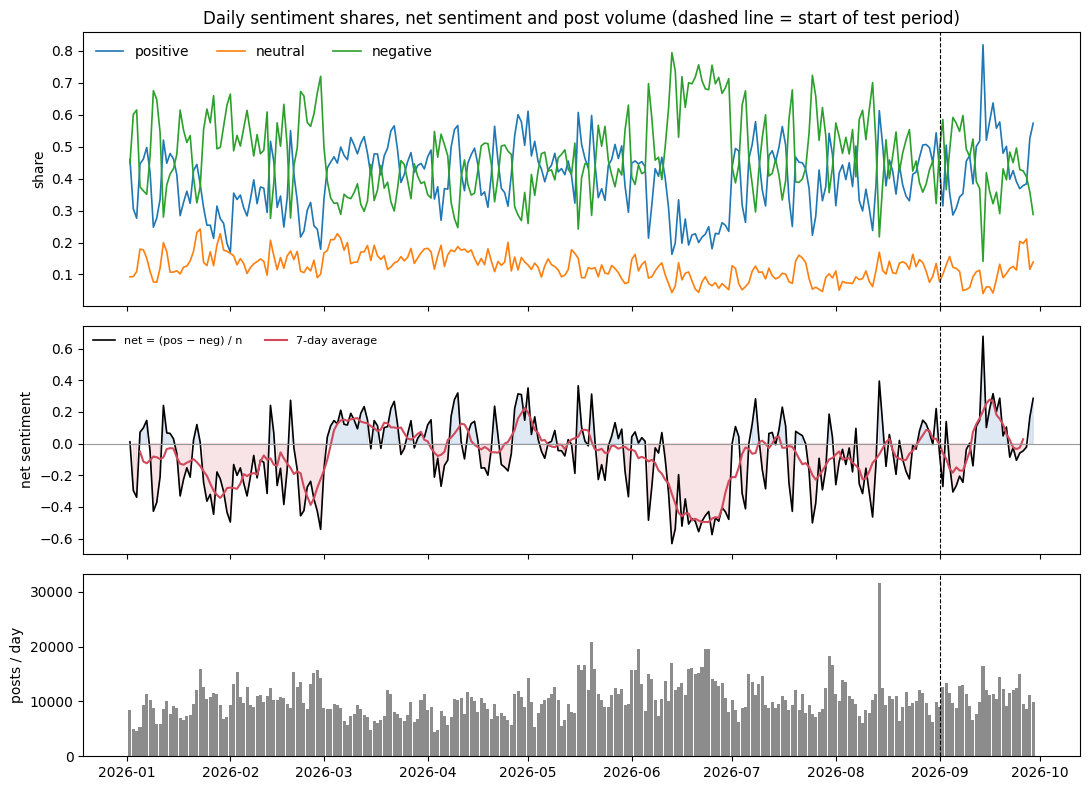

In [23]:
FREQ_HOURS = {'1h': 1, '3h': 3, '6h': 6, '12h': 12, '1d': 24}

def aggregate(posts, freq):
    start = posts.time.min().normalize() + pd.Timedelta(days=1)   # complete days only
    end = posts.time.max().normalize()
    p = posts[(posts.time >= start) & (posts.time < end)]
    counts = p.groupby([pd.Grouper(key='time', freq=freq), 'label']).size().unstack(fill_value=0)
    idx = pd.date_range(start, end, freq=freq, inclusive='left')
    counts = counts.reindex(idx, fill_value=0)
    for k in (-1, 0, 1):
        if k not in counts.columns:
            counts[k] = 0
    a = pd.DataFrame(index=idx)
    a['n_neg'], a['n_neu'], a['n_pos'] = counts[-1], counts[0], counts[1]
    a['n'] = a[['n_neg', 'n_neu', 'n_pos']].sum(axis=1)
    nz = a['n'].replace(0, np.nan)
    a['share_pos'], a['share_neu'], a['share_neg'] = a.n_pos / nz, a.n_neu / nz, a.n_neg / nz
    a['net'] = (a.n_pos - a.n_neg) / nz
    a['is_empty'] = (a.n == 0).astype(int)
    c = ['share_pos', 'share_neu', 'share_neg', 'net']
    a[c] = a[c].ffill().bfill()            # empty bins: carry last shares forward
    a['logn'] = np.log1p(a.n)
    return a

os.makedirs(OUT_DIR, exist_ok=True)
AGGS = {}
for fq in FREQS:
    AGGS[fq] = aggregate(posts, fq)
    AGGS[fq].to_csv(f'{OUT_DIR}/aggregated_{fq}.csv', index_label='bin_start')
    a = AGGS[fq]
    print(f'{fq:>4}: {len(a):6,} bins | posts per bin: median {a.n.median():.0f}, '
          f'min {a.n.min():.0f} | empty bins {a.is_empty.mean():.1%}')

if TEST_START:
    TEST_START_TS = pd.Timestamp(TEST_START, tz=LOCAL_TZ)
else:
    last = posts.time.max()
    TEST_START_TS = pd.Timestamp(year=last.year, month=last.month, day=1, tz=LOCAL_TZ)
print(f'\nTraining data: before {TEST_START_TS.date()} | test: {TEST_START_TS.date()} onwards')

d = aggregate(posts, '1D')
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                       gridspec_kw={'height_ratios': [1.2, 1, 0.8]})
for c, l in (('share_pos', 'positive'), ('share_neu', 'neutral'), ('share_neg', 'negative')):
    ax[0].plot(d.index, d[c], label=l, lw=1.2)
ax[0].set_ylabel('share'); ax[0].legend(frameon=False, ncol=3)
ax[0].set_title('Daily sentiment shares, net sentiment and post volume (dashed line = start of test period)')
ax[1].plot(d.index, d.net, color='k', lw=1.2, label='net = (pos − neg) / n')
ax[1].plot(d.index, d.net.rolling(7, center=True).mean(), color='#d1495b', lw=1.5,
           label='7-day average')
ax[1].fill_between(d.index, 0, d.net, where=d.net >= 0, color='#2a6fbb', alpha=0.15)
ax[1].fill_between(d.index, 0, d.net, where=d.net < 0, color='#d1495b', alpha=0.15)
ax[1].axhline(0, color='0.6', lw=0.8)
ax[1].set_ylabel('net sentiment'); ax[1].legend(frameon=False, ncol=2, fontsize=8, loc='upper left')
ax[2].bar(d.index, d.n, width=0.9, color='0.55'); ax[2].set_ylabel('posts / day')
for a in ax:
    a.axvline(TEST_START_TS, color='k', ls='--', lw=0.8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/series_daily.png', dpi=140); plt.show()

## 5. Preparation: features, test weeks and the "no change" yardstick

**Nothing is predicted in this cell.** It prepares everything the model cells (6, 7, 8) need. It has four jobs.

### Job 1: build the features (the models' inputs)
A model can't read a raw sentiment line. It needs a **table**: one row per moment in time, one column per
piece of information that is already known at that moment. Example row for 13 September 20:00 (row are the time, columns are features):

| Feature | Meaning |
|---|---|
| `y_lag0` | net sentiment now |
| `y_lag1`, `y_lag2` | net sentiment 1 and 2 bins ago |
| `y_mean24` | average net over the last 24 bins |
| `y_std_day` | how much net jumped around during the last day (volatility) |
| `y_dev_week` | how far net is from its 7-day average |
| `share_pos`, `share_neu`, `share_neg` | the shares now (except the one being forecast) |
| `logn` | how many posts there are now (log scale) |
| `logn_surge` | is volume unusually high vs the last 7 days? (**event signal**) |
| `hour_sin/cos`, `dow_sin/cos` | time of day and day of week (as a circle, so 23:00 is close to 00:00) |

XGBoost and LightGBM learn from this table. VAR (cell 8) uses the raw series directly.

### Job 2: set up the test weeks (folds)
The test period (from `TEST_START`) is cut into blocks of `FOLD_DAYS` (7) days. Before each block, the models are retrained on all data before that block, so September data is added as it "arrives":

| Fold | Trained on | Forecasts for |
|---|---|---|
| 1 | 1 Jan – 31 Aug | 1 – 7 Sep |
| 2 | 1 Jan – 7 Sep | 8 – 14 Sep |
| … | … | … |

A model is never allowed to see the value it is forecasting (no "future leakage").

### Job 3: build the "no change" yardstick
For every moment in the test period it records the simplest possible forecast: **the future = the value now.** It is also called the *persistence* or *naive* forecast.
**Why is it needed?** An error number alone means nothing. If XGBoost's average error (MAE) is 0.08, is that good?
We can't tell without something to compare it with. The fairest comparison is the simplest thing to do without a model, **assume nothing changes**. Sentiment usually changes slowly, so "same as now" is often close. That makes it an honest benchmark.

### Job 4: define helper tools used later
* `run_tree_model`: trains XGBoost / LightGBM fold by fold (used in cells 6 and 7)
* `score`: compares a model with "no change"
* `show`: prints the skill table

### How to read **skill** (comparison of model result and 'no change' assumption)
**skill = 1 − (model error ÷ "no change" error)**

| Skill | Meaning |
|---|---|
| 0.30 | the model's error is 30 % smaller than "no change", so it's useful |
| 0 | no better than copying the current value |
| below 0 | **worse** than copying the current value, so the model hurts |

Example from this data: XGBoost with daily bins, 24 h ahead, had skill −0.03, so it was worse than simply copying today's value. Without the yardstick that would have looked like a normal error number.

In [26]:
# JOB 1: FEATURES
# Turn one sentiment series into a table: one row per time bin, one column per
# piece of information that is ALREADY KNOWN at that moment.

def build_features(agg, hours):
    spd  = max(1, 24 // hours)        # bins per day   (1h -> 24, 6h -> 4, 12h -> 2, 1D -> 1)
    week = 7 * spd                    # bins per week
    y    = agg[TARGET]                # the series we forecast (net sentiment by default)
    logn = agg.logn                   # log(1 + number of posts)
    f = pd.DataFrame(index=agg.index)

    # --- past values ("lags"): now, 1 and 2 bins ago, ~1 day ago, ~2 days ago, ~1 week ago
    for L in sorted({0, 1, 2, spd - 1, 2 * spd - 1, week - 1}):
        f[f'y_lag{L}'] = y.shift(L)

    # --- recent averages: last 3 bins, last day, last week
    for w in sorted({3, spd, week}):
        if w >= 2:
            f[f'y_mean{w}'] = y.rolling(w).mean()

    # --- how jumpy, how fast it's changing, how far from normal
    f['y_std_day']  = y.rolling(max(spd, 3)).std()      # volatility over the last day
    f['y_diff1']    = y.diff()                          # change since the previous bin
    f['y_dev_week'] = y - y.rolling(week).mean()        # distance from the 7-day average

    # --- the other sentiment shares right now
    for c in ('share_pos', 'share_neu', 'share_neg'):
        if c != TARGET:
            f[c] = agg[c]

    # --- post volume: level, surge (event signal) and change
    f['logn']       = logn
    f['logn_surge'] = logn - logn.rolling(week).mean()  # > 0 = busier than a normal week -> something happening
    f['logn_diff1'] = logn.diff()
    f['is_empty']   = agg.is_empty                      # 1 if no posts in this bin

    # --- calendar, written as points on a circle so 23:00 sits next to 00:00 (and Sunday next to Monday)
    if spd > 1:                                         # hour of day only makes sense for sub-daily bins
        hr = agg.index.hour + agg.index.minute / 60
        f['hour_sin'] = np.sin(2 * np.pi * hr / 24)
        f['hour_cos'] = np.cos(2 * np.pi * hr / 24)
    f['dow_sin'] = np.sin(2 * np.pi * agg.index.dayofweek / 7)
    f['dow_cos'] = np.cos(2 * np.pi * agg.index.dayofweek / 7)
    return f

# JOB 1 + 2: build the feature table and the test weeks for every bin size
# Everything is stored in DATA[bin size], e.g. DATA['6h'].

DATA = {}
for fq, agg in AGGS.items():
    hours = FREQ_HOURS[fq.lower()]
    feats = build_features(agg, hours)
    X     = feats.to_numpy(float)
    times = agg.index

    # The first rows have no history yet (e.g. no 7-day average in week 1) -> not usable
    valid = ~np.isnan(X).any(axis=1)

    # Weight per bin: bins with more posts are more reliable, so they count a bit more in training
    w = np.sqrt(np.clip(agg.n.to_numpy(float), 1, None)); w /= w.mean()

    # Horizons in "steps" of this bin size. Example with 6h bins: 24h ahead = 4 steps.
    # Horizons shorter than one bin (e.g. 1h ahead with 6h bins) are skipped.
    steps = [h // hours for h in HORIZONS_H if h % hours == 0 and h >= hours]

    # JOB 2: cut the test period into FOLD_DAYS-day blocks ("folds").
    # For each fold store: start date, which bins are forecast, and where training must stop.
    folds = []
    for fold_start in pd.date_range(TEST_START_TS, times[-1], freq=f'{FOLD_DAYS}D'):
        in_fold = (times >= fold_start) & (times < fold_start + pd.Timedelta(days=FOLD_DAYS))
        test_origins = np.where(in_fold & valid)[0]           # moments from which we forecast
        train_end = int(np.searchsorted(times, fold_start))   # first bin the model may NOT train on
        if len(test_origins):
            folds.append((fold_start, test_origins, train_end))

    DATA[fq] = dict(agg=agg, hours=hours, X=X, feature_names=list(feats.columns),
                    y=agg[TARGET].to_numpy(float), w=w, valid=valid, times=times,
                    T=len(agg), steps=steps, folds=folds)
    print(f'{fq:>4}: {len(folds)} test folds, horizons (steps) {steps}, {X.shape[1]} features')


# Small helper: package forecasts into a table with the same columns for every model
def to_frame(name, fq, s, origins, y_true, y_pred):
    D = DATA[fq]
    return pd.DataFrame(dict(model=name, freq=fq, horizon_h=s * D['hours'], origin=origins,
                             origin_time=D['times'][origins], y_true=y_true, y_pred=y_pred))

# JOB 3: the "no change" yardstick
# Forecast for (now + horizon) = value now.  y_true = what really happened.
rows = []
for fq, D in DATA.items():
    for fold_start, test_origins, train_end in D['folds']:
        for s in D['steps']:
            o = test_origins[test_origins + s < D['T']]      # skip forecasts that run past the data
            rows.append(to_frame('persistence', fq, s, o,
                                 y_true=D['y'][o + s],       # actual value at now + horizon
                                 y_pred=D['y'][o]))          # "no change" = value now
PRED = {'persistence': pd.concat(rows, ignore_index=True)}   # all forecasts of all models end up in PRED

# JOB 4: helper tools for the model cells
def score(name):
    """Error of a model and its skill vs "no change", on exactly the same forecast points."""
    P = PRED[name].merge(PRED['persistence'][['freq', 'horizon_h', 'origin', 'y_pred']],
                         on=['freq', 'horizon_h', 'origin'], suffixes=('', '_pers'))
    P['err']      = (P.y_pred - P.y_true).abs()              # model error
    P['err_pers'] = (P.y_pred_pers - P.y_true).abs()         # "no change" error
    P['sq']       = (P.y_pred - P.y_true) ** 2
    S = P.groupby(['freq', 'horizon_h'], sort=False).agg(
        n=('err', 'size'), MAE=('err', 'mean'), MSE=('sq', 'mean'), MAE_pers=('err_pers', 'mean'))
    S['RMSE']  = np.sqrt(S.pop('MSE'))
    S['skill'] = 1 - S.MAE / S.MAE_pers                      # > 0 = better than "no change"
    S.insert(0, 'model', name)
    return S.reset_index()

def show(name):
    """Print the skill table of one model: rows = horizon, columns = bin size."""
    S = score(name)
    print(f'\n{name}: skill vs "no change" (above 0 = better)')
    print(S.pivot(index='horizon_h', columns='freq', values='skill')[list(DATA)].round(3).to_string())

def run_tree_model(name, make_model):
    """Train and test a tree model (XGBoost / LightGBM) fold by fold.
    One separate model per bin size x horizon x fold.
    The model learns the CHANGE from now (y[now + horizon] - y[now]), which works better
    for trees than learning the level itself."""
    rows, last_models = [], {}
    for fq, D in DATA.items():
        t0 = time.time()
        X, y, w, T = D['X'], D['y'], D['w'], D['T']
        for fold_start, test_origins, train_end in D['folds']:
            for s in D['steps']:
                o  = test_origins[test_origins + s < T]
                # training rows: their TARGET (row + s) must lie before the fold -> no future leakage
                tr = np.where(D['valid'] & (np.arange(T) + s < train_end))[0]
                if len(o) == 0 or len(tr) < 50:
                    continue
                m = make_model()
                m.fit(X[tr], y[tr + s] - y[tr], sample_weight=w[tr + s])   # learn: features -> change
                y_hat = y[o] + m.predict(X[o])                             # forecast = now + predicted change
                rows.append(to_frame(name, fq, s, o, y[o + s], y_hat))
                last_models[(fq, s * D['hours'])] = m                      # kept for feature importance (cell 13)
        print(f'  {name} {fq:>4} done in {time.time() - t0:.0f}s')
    return pd.concat(rows, ignore_index=True), last_models

print('\nReady. "No change" yardstick built for', len(PRED['persistence']), 'forecast points.')

  1h: 5 test folds, horizons (steps) [1, 6, 12, 24, 72, 168], 23 features
  6h: 5 test folds, horizons (steps) [1, 2, 4, 12, 28], 23 features
 12h: 5 test folds, horizons (steps) [1, 2, 6, 14], 22 features
  1D: 5 test folds, horizons (steps) [1, 3, 7], 18 features

Ready. "No change" yardstick built for 4711 forecast points.


## 6. XGBoost
Gradient-boosted trees on the features from step 5. Combines weak learner trees that is retrained (or fixed) based on the previous result's residual to form a more accurate model.  
This models make a forecast by asking a long series of simple yes/no questions about the data, such as “Is posting unusually busy today?” or “Was sentiment negative yesterday?” Each chain of questions is called a “tree”. It build hundreds of these trees, each new one fixing the mistakes of the ones before, and add their answers together.
XGBoost asks its questions evenly. It asks one round of questions about every group in the data before going any deeper.  
Settings can be changed in `make_xgb`.

In [29]:
def make_xgb():
    return xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4,
                            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                            reg_lambda=1.0, n_jobs=-1, verbosity=0, random_state=0)

PRED['xgboost'], XGB_MODELS = run_tree_model('xgboost', make_xgb)
show('xgboost')

  xgboost   1h done in 33s
  xgboost   6h done in 17s
  xgboost  12h done in 13s
  xgboost   1D done in 5s

xgboost: skill vs "no change" (above 0 = better)
freq          1h     6h    12h     1D
horizon_h                            
1          0.103    NaN    NaN    NaN
6          0.250  0.142    NaN    NaN
12         0.237  0.170  0.156    NaN
24         0.158 -0.026 -0.015 -0.033
72         0.147  0.056 -0.001 -0.083
168        0.229  0.260  0.316  0.315


## 7. LightGBM
It also has similar mechanism like XGboost. However while XGboost questions on each group evenly, LightGBM asks its questions where they help most. It keeps digging into whichever group is still predicted worst and leaves the rest. It’s faster and sharper, but with little data it can focus too much on details that don’t really matter.  


Same features and setup as XGBoost, different boosting library.

In [30]:
def make_lgb():
    return lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15,
                             min_child_samples=20, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, random_state=0)

PRED['lightgbm'], LGB_MODELS = run_tree_model('lightgbm', make_lgb)
show('lightgbm')

  lightgbm   1h done in 25s
  lightgbm   6h done in 12s
  lightgbm  12h done in 4s
  lightgbm   1D done in 1s

lightgbm: skill vs "no change" (above 0 = better)
freq          1h     6h    12h     1D
horizon_h                            
1          0.102    NaN    NaN    NaN
6          0.241  0.137    NaN    NaN
12         0.236  0.187  0.113    NaN
24         0.154 -0.044 -0.079 -0.100
72         0.142  0.060  0.025 -0.137
168        0.232  0.269  0.289  0.347


## 8. VAR
VAR (Vector Autoregression) forecasts using a simple formula. The next value is a weighted mix of recent past values. It follows three series together (net sentiment, neutral share and post volume), so it can capture how they influence each other, for example a sudden burst of posts pushing sentiment down the next day. The regular daily and weekly rhythm is included as a fixed background pattern. To forecast further ahead, it predicts one step at a time and builds on its own predictions.

Its limitation is that it only captures straight-line relationships, so it can miss more complex patterns that tree models may find.

In [31]:
VAR_VARS = ['net', 'share_neu', 'logn']
P_MAX = {1: 24, 3: 16, 6: 8, 12: 6, 24: 7}      # largest lag tried, per bin size (hours)

def fourier_terms(index, hours):
    t_h = np.asarray((index - index[0]) / pd.Timedelta(hours=1), float)
    cols = []
    if hours < 24:
        for k in (1, 2, 3):
            cols += [np.sin(2 * np.pi * k * t_h / 24), np.cos(2 * np.pi * k * t_h / 24)]
    for k in (1, 2):
        cols += [np.sin(2 * np.pi * k * t_h / 168), np.cos(2 * np.pi * k * t_h / 168)]
    return np.column_stack(cols)

def var_design(Z, E, p, rows):
    return np.hstack([np.ones((len(rows), 1)), E[rows]] + [Z[rows - L] for L in range(1, p + 1)])

def fit_var(Z, E, train_end, p_max, ridge=1e-3):
    rows = np.arange(p_max, train_end)
    Y, best = Z[rows], None
    for p in range(1, p_max + 1):
        X = var_design(Z, E, p, rows)
        B = np.linalg.solve(X.T @ X + ridge * np.eye(X.shape[1]), X.T @ Y)
        R = Y - X @ B
        bic = np.linalg.slogdet(R.T @ R / len(rows))[1] + B.size * np.log(len(rows)) / len(rows)
        if best is None or bic < best[0]:
            best = (bic, p, B)
    return best[1], best[2]

def forecast_var(Z, E, p, B, origins, max_steps):
    n, k, T = len(origins), Z.shape[1], len(Z)
    lags = np.stack([Z[origins - L] for L in range(p)], axis=1)
    out = np.full((n, max_steps, k), np.nan)
    for s in range(1, max_steps + 1):
        tgt = origins + s
        X = np.hstack([np.ones((n, 1)), E[np.minimum(tgt, T - 1)], lags.reshape(n, p * k)])
        z = X @ B
        z[tgt >= T] = np.nan
        out[:, s - 1] = z
        lags = np.concatenate([z[:, None, :], lags[:, :-1]], axis=1)
    return out

def var_target(z):
    net, neu = z[..., 0], z[..., 1]
    return {'net': net, 'share_neu': neu, 'share_pos': (1 - neu + net) / 2,
            'share_neg': (1 - neu - net) / 2}[TARGET]

rows, VAR_FITS = [], {}
for fq, D in DATA.items():
    Z = D['agg'][VAR_VARS].to_numpy(float)
    E = fourier_terms(D['times'], D['hours'])
    p_max, max_steps = P_MAX.get(D['hours'], 7), max(D['steps'])
    chosen = []
    for fs, test_orig, train_end in D['folds']:
        p, B = fit_var(Z, E, train_end, p_max)
        chosen.append(p)
        vo = test_orig[test_orig >= p]
        yhat = var_target(forecast_var(Z, E, p, B, vo, max_steps))
        for s in D['steps']:
            ok = vo + s < D['T']
            rows.append(to_frame('var', fq, s, vo[ok], D['y'][vo[ok] + s], yhat[ok, s - 1]))
    VAR_FITS[fq] = (p, B)
    note = '  <- hit the maximum, consider raising P_MAX' if max(chosen) == p_max else ''
    print(f'  var {fq:>4}: lag order p per fold = {chosen}{note}')
PRED['var'] = pd.concat(rows, ignore_index=True)
show('var')

  var   1h: lag order p per fold = [7, 7, 7, 7, 7]
  var   6h: lag order p per fold = [4, 4, 4, 4, 4]
  var  12h: lag order p per fold = [2, 2, 2, 2, 2]
  var   1D: lag order p per fold = [1, 1, 1, 1, 1]

var: skill vs "no change" (above 0 = better)
freq          1h     6h    12h     1D
horizon_h                            
1          0.109    NaN    NaN    NaN
6          0.243  0.159    NaN    NaN
12         0.242  0.201  0.244    NaN
24         0.131  0.095  0.090  0.055
72         0.117  0.097  0.038  0.025
168        0.241  0.291  0.278  0.273


## 9. Compare all models + save

Skill vs "no change" (above 0 = better):


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.109    0.103     0.102
     6          0.243    0.250     0.241
     12         0.242    0.237     0.236
     24         0.131    0.158     0.154
     72         0.117    0.147     0.142
     168        0.241    0.229     0.232
6h   6          0.159    0.142     0.137
     12         0.201    0.170     0.187
     24         0.095   -0.026    -0.044
     72         0.097    0.056     0.060
     168        0.291    0.260     0.269
12h  12         0.244    0.156     0.113
     24         0.090   -0.015    -0.079
     72         0.038   -0.001     0.025
     168        0.278    0.316     0.289
1D   24         0.055   -0.033    -0.100
     72         0.025   -0.083    -0.137
     168        0.273    0.315     0.347

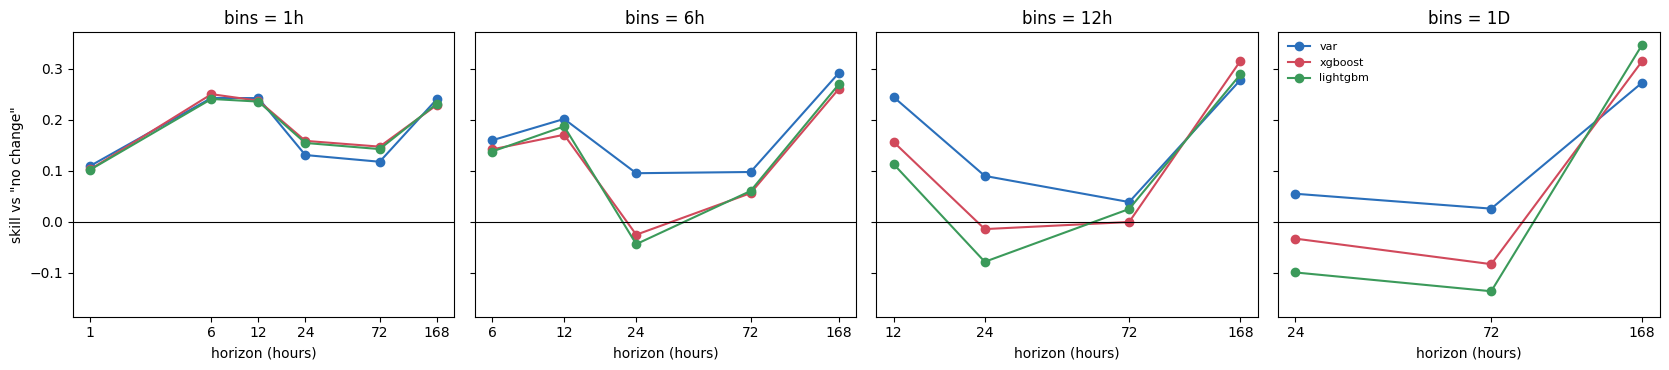

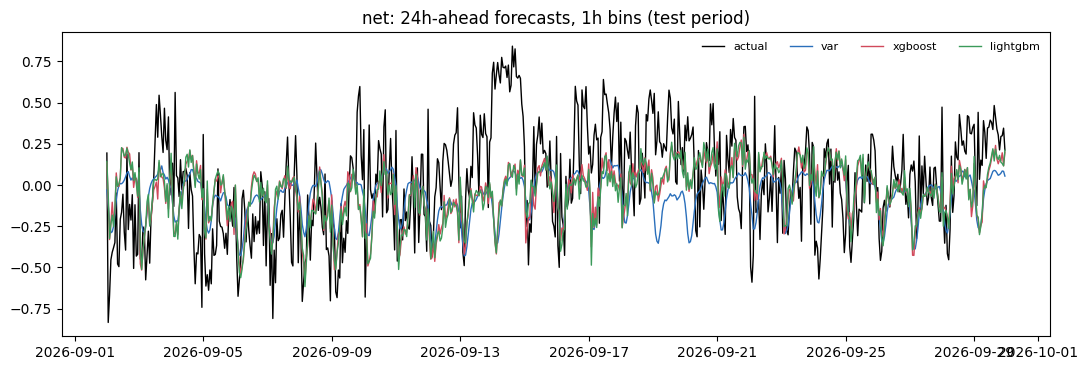

Saved to /content/drive/MyDrive/sentiment_project/results


In [32]:
models = [m for m in ('var', 'xgboost', 'lightgbm') if m in PRED]
SCORES = pd.concat([score(m) for m in models], ignore_index=True)
SCORES.to_csv(f'{OUT_DIR}/scores.csv', index=False)
pd.concat(PRED.values(), ignore_index=True).drop(columns='origin').to_csv(
    f'{OUT_DIR}/predictions.csv', index=False)

print('Skill vs "no change" (above 0 = better):')
display(SCORES.pivot_table(index=['freq', 'horizon_h'], columns='model', values='skill',
                           sort=False)[models].round(3))

colors = {'var': '#2a6fbb', 'xgboost': '#d1495b', 'lightgbm': '#3b9a5a'}
fig, axes = plt.subplots(1, len(DATA), figsize=(4.2 * len(DATA), 3.8), sharey=True, squeeze=False)
for ax, fq in zip(axes[0], DATA):
    g = SCORES[SCORES.freq == fq]
    for m in models:
        gm = g[g.model == m].sort_values('horizon_h')
        ax.plot(gm.horizon_h, gm.skill, marker='o', label=m, color=colors[m])
    hs = sorted(g.horizon_h.unique())
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xscale('log'); ax.set_xticks(hs); ax.set_xticklabels(hs); ax.minorticks_off()
    ax.set_title(f'bins = {fq}'); ax.set_xlabel('horizon (hours)')
axes[0][0].set_ylabel('skill vs "no change"')
axes[0][0].set_ylim(max(-1, SCORES.skill.min() - 0.05), None)
axes[0][-1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/skill_by_horizon.png', dpi=140); plt.show()

# example: 24h-ahead forecasts with the finest bins
fq = list(DATA)[0]; h = 24
fig, ax = plt.subplots(figsize=(11, 3.8))
ref = PRED['persistence'].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
ax.plot(ref.origin_time + pd.Timedelta(hours=h), ref.y_true, color='k', lw=1, label='actual')
for m in models:
    g = PRED[m].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
    ax.plot(g.origin_time + pd.Timedelta(hours=h), g.y_pred, lw=1, label=m, color=colors[m])
ax.set_title(f'{TARGET}: {h}h-ahead forecasts, {fq} bins (test period)')
ax.legend(frameon=False, ncol=4, fontsize=8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/forecast_example.png', dpi=140); plt.show()
print('Saved to', os.path.abspath(OUT_DIR))

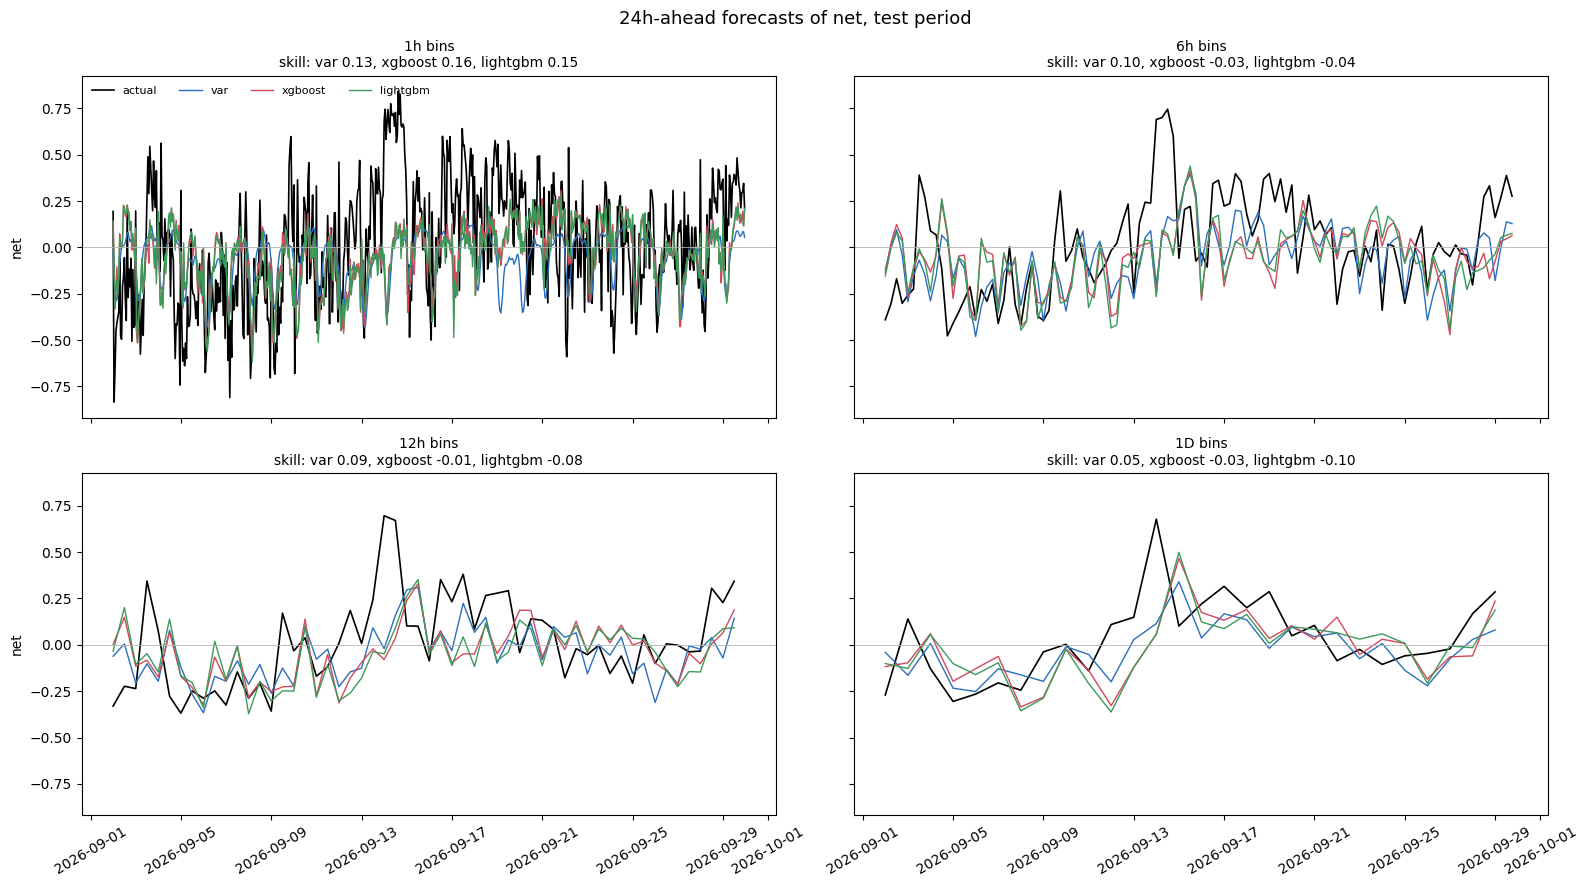

In [33]:
# 24h-ahead forecasts: the four bin sizes in a 2x2 grid
# top left = 1h, top right = 6h, bottom left = 12h, bottom right = 1D
h = 24
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
for ax, fq in zip(axes.ravel(), DATA):
    ref = PRED['persistence'].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
    if ref.empty:
        ax.set_title(f'{fq} bins: no {h}h horizon'); continue
    ax.plot(ref.origin_time + pd.Timedelta(hours=h), ref.y_true, color='k', lw=1.2, label='actual')
    for m in models:
        g = PRED[m].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
        ax.plot(g.origin_time + pd.Timedelta(hours=h), g.y_pred, lw=1, label=m, color=colors[m])
    ax.axhline(0, color='0.7', lw=0.6)
    sk = SCORES.query('freq == @fq and horizon_h == @h').set_index('model').skill
    ax.set_title(f'{fq} bins\nskill: ' + ', '.join(f'{m} {sk[m]:.2f}' for m in models if m in sk),
                 fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel(TARGET)
for ax in axes[1]:
    ax.tick_params(axis='x', labelrotation=30)
for ax in axes.ravel()[len(DATA):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, ncol=4, fontsize=8, loc='upper left')
fig.suptitle(f'{h}h-ahead forecasts of {TARGET}, test period', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/forecast_all_bins.png', dpi=140, bbox_inches='tight'); plt.show()

In [35]:
# ===== Extra evaluation metrics for =====
#  MAE        average size of the error (same unit as the target)
#  RMSE       like MAE but punishes big misses more
#  bias       average error; > 0 = model forecasts too high on average
#  R2         1 - SSE/SST on the test period (1 = perfect, 0 = no better than the test mean,
#             can be negative)
#  corr       correlation between forecast and actual (pattern match, ignores level)
#  dir_acc    share of forecasts that get the DIRECTION of change right (up vs down)
#  skill      1 - MAE / MAE("no change")
rows = []
pers = PRED['persistence'][['freq', 'horizon_h', 'origin', 'y_pred']].rename(columns={'y_pred': 'y_now'})
for m in models:
    P = PRED[m].merge(pers, on=['freq', 'horizon_h', 'origin'])
    for (fq, h), g in P.groupby(['freq', 'horizon_h'], sort=False):
        e = g.y_pred - g.y_true
        sst = ((g.y_true - g.y_true.mean()) ** 2).sum()
        moved = (g.y_true - g.y_now) != 0
        rows.append(dict(
            freq=fq, horizon_h=h, model=m,
            MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()), bias=e.mean(),
            R2=1 - (e ** 2).sum() / sst,
            corr=np.corrcoef(g.y_pred, g.y_true)[0, 1],
            dir_acc=(np.sign(g.y_pred - g.y_now) == np.sign(g.y_true - g.y_now))[moved].mean()))
METRICS = pd.DataFrame(rows).merge(SCORES[['freq', 'horizon_h', 'model', 'skill']],
                                   on=['freq', 'horizon_h', 'model'])
METRICS.to_csv(f'{OUT_DIR}/metrics.csv', index=False)
for col in ('MAE', 'RMSE', 'R2', 'dir_acc'):
    print(f'\n{col}')
    display(METRICS.pivot_table(index=['freq', 'horizon_h'], columns='model', values=col,
                                sort=False)[models].round(3))
print('\nAll metrics saved to', f'{OUT_DIR}/metrics.csv')


MAE


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.173    0.174     0.175
     6          0.207    0.205     0.208
     12         0.230    0.232     0.232
     24         0.254    0.246     0.247
     72         0.260    0.251     0.252
     168        0.268    0.272     0.271
6h   6          0.132    0.135     0.135
     12         0.161    0.167     0.164
     24         0.194    0.220     0.224
     72         0.210    0.219     0.218
     168        0.234    0.244     0.241
12h  12         0.123    0.138     0.145
     24         0.173    0.193     0.206
     72         0.193    0.201     0.195
     168        0.219    0.208     0.216
1D   24         0.149    0.163     0.174
     72         0.173    0.192     0.202
     168        0.209    0.197     0.188


RMSE


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.221    0.219     0.220
     6          0.260    0.257     0.261
     12         0.287    0.291     0.291
     24         0.315    0.306     0.309
     72         0.324    0.316     0.319
     168        0.334    0.342     0.341
6h   6          0.178    0.178     0.177
     12         0.209    0.218     0.215
     24         0.243    0.273     0.274
     72         0.275    0.285     0.283
     168        0.305    0.331     0.326
12h  12         0.168    0.191     0.194
     24         0.221    0.247     0.253
     72         0.249    0.269     0.264
     168        0.279    0.281     0.295
1D   24         0.189    0.214     0.223
     72         0.232    0.259     0.264
     168        0.271    0.258     0.263


R2


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.513    0.520     0.518
     6          0.329    0.340     0.321
     12         0.185    0.164     0.163
     24         0.027    0.080     0.065
     72        -0.063   -0.012    -0.030
     168       -0.229   -0.288    -0.278
6h   6          0.525    0.527     0.532
     12         0.354    0.293     0.311
     24         0.130   -0.095    -0.104
     72        -0.141   -0.225    -0.206
     168       -0.586   -0.865    -0.808
12h  12         0.503    0.364     0.341
     24         0.161   -0.049    -0.108
     72        -0.117   -0.298    -0.257
     168       -0.599   -0.624    -0.795
1D   24         0.228    0.010    -0.074
     72        -0.176   -0.469    -0.526
     168       -0.926   -0.741    -0.819


dir_acc


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.665    0.701     0.698
     6          0.733    0.749     0.754
     12         0.753    0.765     0.769
     24         0.702    0.699     0.698
     72         0.712    0.704     0.697
     168        0.742    0.737     0.748
6h   6          0.704    0.713     0.696
     12         0.746    0.763     0.772
     24         0.580    0.643     0.670
     72         0.644    0.654     0.635
     168        0.761    0.693     0.739
12h  12         0.825    0.737     0.772
     24         0.643    0.607     0.607
     72         0.577    0.615     0.635
     168        0.795    0.705     0.682
1D   24         0.500    0.571     0.679
     72         0.654    0.615     0.615
     168        0.727    0.682     0.773


All metrics saved to results/metrics.csv


Method: mean |SHAP| | horizon 24h | share_% = share of total importance

Share of importance by feature group (%)


group          net history  other shares  post volume  calendar
freq model                                                     
1h   xgboost          54.4          13.4         11.2      21.0
     lightgbm         53.6          13.8         11.1      21.5
6h   xgboost          54.1          14.6         17.0      14.2
     lightgbm         52.9          14.9         16.7      15.5
12h  xgboost          58.2          12.4         17.5      12.0
     lightgbm         57.7          12.4         17.8      12.1
1D   xgboost          50.2          19.9         16.7      13.1
     lightgbm         49.8          17.9         18.1      14.3

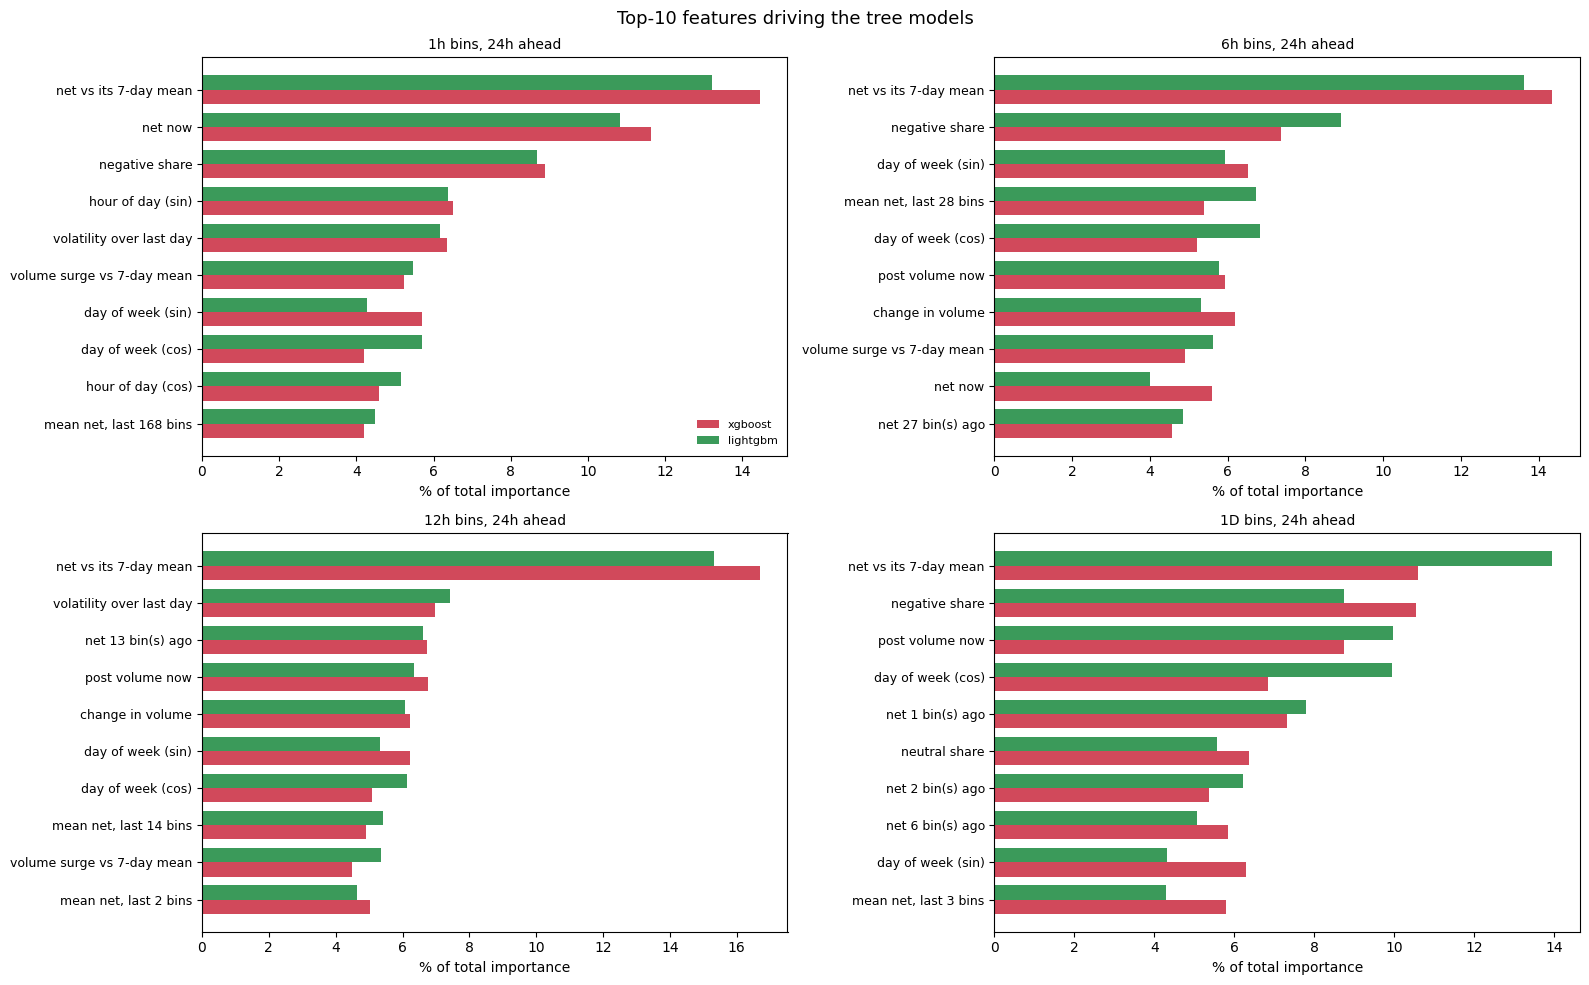

In [36]:
# ===== 13. Which features drive XGBoost / LightGBM? =====
# Uses the models fitted in cells 6-7 (last test fold) and explains their forecasts
# on the test period with SHAP values: how much each feature moves the forecast, on average.
H_EXPLAIN = 24          # horizon (hours) to explain; must exist for the bin sizes

FEATURE_INFO = {
    'y_lag0': 'net now', 'y_diff1': 'change since last bin', 'y_dev_week': 'net vs its 7-day mean',
    'y_std_day': 'volatility over last day', 'logn': 'post volume now',
    'logn_surge': 'volume surge vs 7-day mean', 'logn_diff1': 'change in volume',
    'share_neu': 'neutral share', 'share_pos': 'positive share', 'share_neg': 'negative share',
    'hour_sin': 'hour of day (sin)', 'hour_cos': 'hour of day (cos)',
    'dow_sin': 'day of week (sin)', 'dow_cos': 'day of week (cos)', 'is_empty': 'empty bin flag'}
def describe(f):
    if f in FEATURE_INFO: return FEATURE_INFO[f]
    if f.startswith('y_lag'): return f'net {f[5:]} bin(s) ago'
    if f.startswith('y_mean'): return f'mean net, last {f[6:]} bins'
    return f
def feature_group(f):
    if f.startswith('y_'): return f'{TARGET} history'
    if f.startswith('logn') or f == 'is_empty': return 'post volume'
    if f.startswith('share'): return 'other shares'
    return 'calendar'

def importance(name, m, X, y_delta):
    """mean |SHAP| (native in xgboost / lightgbm); falls back to permutation importance."""
    try:
        if name == 'xgboost':
            c = m.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
        else:
            c = m.predict(X, pred_contrib=True)
        return np.abs(np.asarray(c)[:, :-1]).mean(0), 'mean |SHAP|'
    except Exception:
        from sklearn.inspection import permutation_importance
        r = permutation_importance(m, X, y_delta, n_repeats=5, random_state=0,
                                   scoring='neg_mean_absolute_error')
        return np.clip(r.importances_mean, 0, None), 'permutation importance'

IMP_ROWS = []
for fq, D in DATA.items():
    s = H_EXPLAIN // D['hours']
    if H_EXPLAIN % D['hours']:
        continue
    idx = np.where((D['times'] >= TEST_START_TS) & D['valid'] & (np.arange(D['T']) + s < D['T']))[0]
    Xt, yd = D['X'][idx], D['y'][idx + s] - D['y'][idx]
    for name, store in (('xgboost', XGB_MODELS), ('lightgbm', LGB_MODELS)):
        m = store.get((fq, H_EXPLAIN))
        if m is None:
            continue
        imp, how = importance(name, m, Xt, yd)
        for f, v in zip(D['feature_names'], imp):
            IMP_ROWS.append(dict(freq=fq, model=name, feature=f, description=describe(f),
                                 group=feature_group(f), importance=v, method=how))
IMP = pd.DataFrame(IMP_ROWS)
IMP['share_%'] = 100 * IMP.importance / IMP.groupby(['freq', 'model']).importance.transform('sum')
IMP.to_csv(f'{OUT_DIR}/feature_importance_trees.csv', index=False)
print(f'Method: {IMP.method.iloc[0]} | horizon {H_EXPLAIN}h | share_% = share of total importance\n')

# importance by feature group (comparable with the VAR breakdown in cell 14)
TREE_GROUP_SHARE = IMP.pivot_table(index=['freq', 'model'], columns='group', values='share_%',
                                   aggfunc='sum', sort=False).round(1)
print('Share of importance by feature group (%)')
display(TREE_GROUP_SHARE)

# top-10 features per bin size: 2x2 grid, xgboost and lightgbm side by side
freqs_imp = list(dict.fromkeys(IMP.freq))
fig, axes = plt.subplots(2, 2, figsize=(16, 10), squeeze=False)
for ax, fq in zip(axes.ravel(), freqs_imp):
    g = IMP[IMP.freq == fq]
    top = g.groupby('description')['share_%'].mean().nlargest(10).index[::-1]
    yy = np.arange(len(top))
    for j, name in enumerate(('xgboost', 'lightgbm')):
        v = g[g.model == name].set_index('description')['share_%'].reindex(top).fillna(0)
        ax.barh(yy + (j - 0.5) * 0.38, v, height=0.38, color=colors[name], label=name)
    ax.set_yticks(yy); ax.set_yticklabels(top, fontsize=9)
    ax.set_xlabel('% of total importance'); ax.set_title(f'{fq} bins, {H_EXPLAIN}h ahead', fontsize=10)
for ax in axes.ravel()[len(freqs_imp):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Top-10 features driving the tree models', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/feature_importance_trees.png', dpi=140, bbox_inches='tight'); plt.show()

FEVD: where the uncertainty of the NET forecast comes from (% , rows sum to 100)


p  post volume  neutral share  net sentiment
freq horizon_h                                              
1h   24         7         23.9            6.7           69.5
     168        7         23.6            7.0           69.4
6h   24         4          2.9           14.7           82.4
     168        4          9.1           16.1           74.8
12h  24         2          0.2           17.0           82.8
     168        2          6.3           16.9           76.8
1D   24         1          2.6           23.0           74.4
     168        1          4.7           24.8           70.5


Granger causality (p < 0.05 = the cause helps predict the effect)


freq                               1h        6h       12h        1D
cause         effect                                               
neutral share net sentiment    0.0166     0.945     0.511     0.646
              post volume    2.09e-06     0.192     0.684     0.546
post volume   net sentiment   0.00048  0.000126    0.0639   0.00522
              neutral share   0.00018   0.00651   0.00224  0.000557
net sentiment neutral share  5.69e-05     0.337     0.323    0.0914
              post volume    4.22e-11  2.07e-06  0.000302    0.0411


Half-life of a shock to net sentiment (hours until its effect is halved):
{'1h': 1, '6h': 12, '12h': 36, '1D': 48}


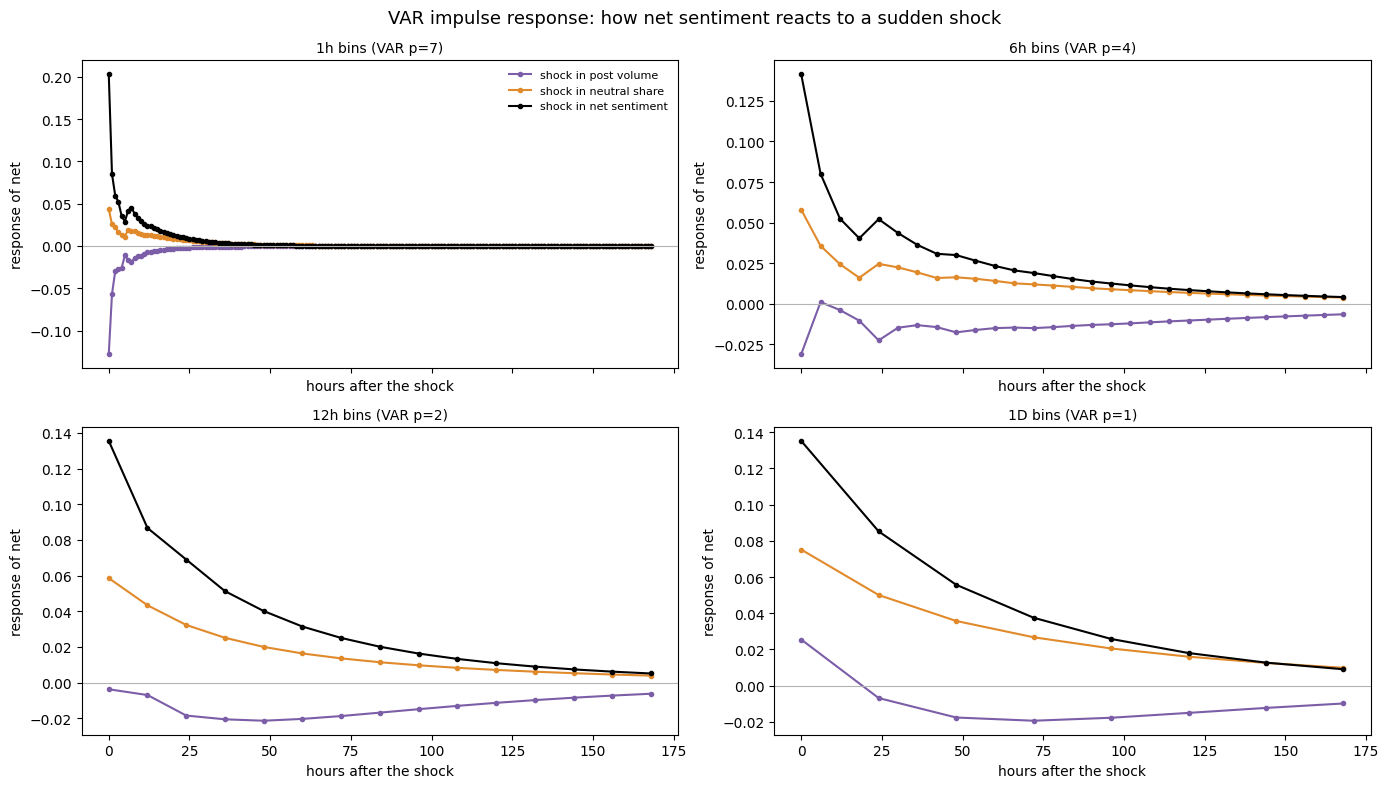


Comparison (different methods, compare the ranking rather than the exact %):
    1h | VAR FEVD: own net 70%, volume 24%, neutral 7%  | trees (xgb): net history 54%, volume 11%, shares 13%, calendar 21%
    6h | VAR FEVD: own net 82%, volume 3%, neutral 15%  | trees (xgb): net history 54%, volume 17%, shares 15%, calendar 14%
   12h | VAR FEVD: own net 83%, volume 0%, neutral 17%  | trees (xgb): net history 58%, volume 18%, shares 12%, calendar 12%
    1D | VAR FEVD: own net 74%, volume 3%, neutral 23%  | trees (xgb): net history 50%, volume 17%, shares 20%, calendar 13%


In [37]:
# ===== 14. What drives VAR? (FEVD, Granger causality, impulse response) =====
# VAR has no "features"; its equivalents are:
#  FEVD     % of the uncertainty in the net forecast that comes from shocks to each variable
#  Granger  does variable X help predict net (beyond net's own past)? p < 0.05 = yes
#  IRF      how net responds over time when one variable gets a sudden 1-SD shock
# Shocks are separated with a Cholesky ordering: volume first, then neutral share, then net
# (net may react within the same bin to volume and neutral; not the other way round).
# The daily/weekly rhythm (sine/cosine terms) is a fixed pattern and not part of these numbers.
from scipy import stats

VAR_ORDER = ['logn', 'share_neu', 'net']
NAMES = {'logn': 'post volume', 'share_neu': 'neutral share', 'net': 'net sentiment'}
H_LIST = [24, 168]
IRF_DAYS = 7

def ma_coefs(A, n):
    k = A[0].shape[0]; Phi = [np.eye(k)]
    for s in range(1, n):
        Phi.append(sum(A[i] @ Phi[s - 1 - i] for i in range(min(s, len(A)))))
    return Phi

FEVD_ROWS, GRANGER_ROWS, IRF = [], [], {}
for fq, D in DATA.items():
    hours, times = D['hours'], D['times']
    T0 = int(np.searchsorted(times, TEST_START_TS))
    Z = D['agg'][VAR_VARS].to_numpy(float); E = fourier_terms(times, hours)
    p, Bv = fit_var(Z, E, T0, P_MAX.get(hours, 7))
    k, ne = Z.shape[1], E.shape[1]; off = 1 + ne
    rows = np.arange(p, T0)
    Xu = var_design(Z, E, p, rows); R = Z[rows] - Xu @ Bv
    Sigma = R.T @ R / len(rows)
    A = [Bv[off + L * k: off + (L + 1) * k, :].T for L in range(p)]
    o = [VAR_VARS.index(v) for v in VAR_ORDER]
    A_o = [a[np.ix_(o, o)] for a in A]
    P = np.linalg.cholesky(Sigma[np.ix_(o, o)])
    n_steps = max(IRF_DAYS * 24 // hours, max(H_LIST) // hours) + 1
    theta = [Ph @ P for Ph in ma_coefs(A_o, n_steps)]          # orthogonalised responses
    i_net = VAR_ORDER.index('net')
    # FEVD of net
    for h in H_LIST:
        H = h // hours
        if h % hours or H < 1: continue
        contrib = np.array([sum(theta[s][i_net, j] ** 2 for s in range(H)) for j in range(k)])
        FEVD_ROWS.append(dict(freq=fq, horizon_h=h, p=p,
                              **{NAMES[v]: 100 * contrib[j] / contrib.sum() for j, v in enumerate(VAR_ORDER)}))
    # Granger causality: every ordered pair
    for c in VAR_VARS:
        ic = VAR_VARS.index(c)
        ssr_u = ((Z[rows, ic] - Xu @ np.linalg.lstsq(Xu, Z[rows, ic], rcond=None)[0]) ** 2).sum()
        for g_ in VAR_VARS:
            if g_ == c: continue
            ig = VAR_VARS.index(g_)
            drop = [off + L * k + ig for L in range(p)]
            Xr = np.delete(Xu, drop, axis=1)
            ssr_r = ((Z[rows, ic] - Xr @ np.linalg.lstsq(Xr, Z[rows, ic], rcond=None)[0]) ** 2).sum()
            df2 = len(rows) - Xu.shape[1]
            F = ((ssr_r - ssr_u) / p) / (ssr_u / df2)
            GRANGER_ROWS.append(dict(freq=fq, cause=NAMES[g_], effect=NAMES[c], F=F,
                                     p_value=stats.f.sf(F, p, df2)))
    # IRF of net, and half-life of a shock to net itself
    own = np.array([theta[s][i_net, i_net] for s in range(n_steps)])
    below = np.where(np.abs(own) <= 0.5 * abs(own[0]))[0]
    IRF[fq] = dict(hours=hours, theta=theta, p=p,
                   half_life_h=(int(below[0] * hours) if len(below) else None))

FEVD = pd.DataFrame(FEVD_ROWS).round(1)
GRANGER = pd.DataFrame(GRANGER_ROWS)
GRANGER['significant'] = np.where(GRANGER.p_value < 0.05, 'yes', 'no')
FEVD.to_csv(f'{OUT_DIR}/var_fevd.csv', index=False); GRANGER.to_csv(f'{OUT_DIR}/var_granger.csv', index=False)

print('FEVD: where the uncertainty of the NET forecast comes from (% , rows sum to 100)')
display(FEVD.set_index(['freq', 'horizon_h']))
print('\nGranger causality (p < 0.05 = the cause helps predict the effect)')
display(GRANGER.pivot_table(index=['cause', 'effect'], columns='freq', values='p_value',
                            sort=False)[list(DATA)].map(lambda v: f'{v:.3g}'))
print('\nHalf-life of a shock to net sentiment (hours until its effect is halved):')
print({fq: v['half_life_h'] for fq, v in IRF.items()})

# IRF plot: response of net to a 1-SD shock in each variable, 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, squeeze=False)
shock_col = {'logn': '#7b5ea7', 'share_neu': '#e08a2c', 'net': 'k'}
for ax, (fq, v) in zip(axes.ravel(), IRF.items()):
    n = IRF_DAYS * 24 // v['hours'] + 1
    x = np.arange(n) * v['hours']
    for j, var in enumerate(VAR_ORDER):
        ax.plot(x, [v['theta'][s][i_net, j] for s in range(n)], marker='o', ms=3,
                color=shock_col[var], label=f'shock in {NAMES[var]}')
    ax.axhline(0, color='0.7', lw=0.8)
    ax.set_title(f'{fq} bins (VAR p={v["p"]})', fontsize=10)
    ax.set_xlabel('hours after the shock'); ax.set_ylabel('response of net')
for ax in axes.ravel()[len(IRF):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle('VAR impulse response: how net sentiment reacts to a sudden shock', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/var_impulse_response.png', dpi=140, bbox_inches='tight'); plt.show()

# side-by-side summary with the tree models (if cell 13 was run)
if 'TREE_GROUP_SHARE' in globals():
    print('\nComparison (different methods, compare the ranking rather than the exact %):')
    for fq in DATA:
        f24 = FEVD[(FEVD.freq == fq) & (FEVD.horizon_h == 24)]
        if f24.empty or fq not in TREE_GROUP_SHARE.index.get_level_values(0): continue
        tv = TREE_GROUP_SHARE.loc[fq]
        print(f'  {fq:>4} | VAR FEVD: own net {f24["net sentiment"].iloc[0]:.0f}%, '
              f'volume {f24["post volume"].iloc[0]:.0f}%, neutral {f24["neutral share"].iloc[0]:.0f}%'
              f'  | trees (xgb): net history {tv.loc["xgboost"].get(f"{TARGET} history", 0):.0f}%, '
              f'volume {tv.loc["xgboost"].get("post volume", 0):.0f}%, '
              f'shares {tv.loc["xgboost"].get("other shares", 0):.0f}%, '
              f'calendar {tv.loc["xgboost"].get("calendar", 0):.0f}%')